# Acoustic Topo-Lock | ASVspoof 2019 PA replay detection

This notebook uses the [public simulated PA release](https://doi.org/10.7488/ds/2555) for replay detection only. Read the [release and attribution terms](https://datashare.ed.ac.uk/items/31074a11-b6f6-4e92-a4ad-07093f8c0c45) before running. PA.zip is listed as 16.45 GB; the default free space check requires 19 GiB for a fresh download. Audio is read from the ZIP, so it is never extracted. You do not need the dataset on your computer.

Run the notebook once with `RUN_FULL = False`. Review the printed archive inspection and smoke report, then set `RUN_FULL = True` and rerun the configuration and full run cells. Smoke runs fit small train/dev subsets, skip evaluation and do not export a model. A CPU runtime is sufficient; full extraction and comparison may outlast a short Colab session.

In [88]:
from pathlib import Path
from datetime import datetime, timezone
import json, os, subprocess, sys

# @title Runtime settings
REPO_URL = ""  # @param {type:"string"}
REPO_REF = ""  # @param {type:"string"}
RUN_FULL = True  # @param {type:"boolean"}
USE_DRIVE = False  # @param {type:"boolean"}

WORK = Path("/content")
SOURCE = WORK / "topolock-source"
DATA = WORK / "acoustic-topo-lock-pa"
ARCHIVE = Path("/content/PA.zip")
OUTPUT = DATA / "results"
print("ARCHIVE:", ARCHIVE)

ARCHIVE: /content/PA.zip


In [89]:
import os, subprocess
URL = "https://zenodo.org/records/6906306/files/PA.zip?download=1"
EXPECTED = 17662711934
if subprocess.run(["pgrep", "wget"], capture_output=True).returncode == 0:
    print("wget already running - not starting another")
elif os.path.exists("/content/PA.zip") and os.path.getsize("/content/PA.zip") == EXPECTED:
    print("File already complete")
else:
    subprocess.Popen(["wget", "-c", "-o", "/content/wget.log", URL, "-O", "/content/PA.zip"],
                     start_new_session=True)
    print("Download started")

File already complete


In [90]:
import io
from zipfile import ZipFile

MODULE = SOURCE / "replay_detection"
if not (MODULE / "pyproject.toml").is_file():
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload only the source ZIP.")
    with ZipFile(io.BytesIO(next(iter(uploaded.values())))) as bundle:
        entries = bundle.infolist()
        if sum(e.file_size for e in entries) > 8_000_000:
            raise ValueError("Use the source ZIP, not the dataset ZIP.")
        for e in entries:
            target = (SOURCE / e.filename).resolve()
            if not target.is_relative_to(MODULE.resolve()) or "\\" in e.filename:
                raise ValueError("Unexpected path in source ZIP.")
        bundle.extractall(SOURCE)

subprocess.run([sys.executable, "-m", "pip", "install", "-e", f"{MODULE}[test]"], check=True)
CONFIG = MODULE / "configs" / "replay_config.yaml"
subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=MODULE, check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q'], returncode=0)

The next cell downloads from Edinburgh DataShare only if the archive is absent. Interrupted transfers retain a `.part` file for retry when the server supports byte ranges. If the official host asks for access or terms acceptance, complete that step through the publisher and point `ARCHIVE` to the resulting authorized cloud copy. Review the discovered member names, protocol column counts, partition counts, label counts and key hashes before running training.

In [75]:
import os
size = os.path.getsize("/content/PA.zip")
print(f"{size:,} / 17,662,711,934  ({size/17662711934:.1%})")
!pgrep -c wget

17,662,711,934 / 17,662,711,934  (100.0%)
0


In [76]:
import os
size = os.path.getsize("/content/PA.zip")
print("size ok:", size == 17662711934)
!md5sum /content/PA.zip

size ok: True
d04677b4f51f4fa6755bf5572beefc04  /content/PA.zip


In [91]:
import subprocess, sys
subprocess.run(
    [sys.executable, "-m", "replay_detection.dataset_loader", str(ARCHIVE)],
    cwd=MODULE, check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'replay_detection.dataset_loader', '/content/PA.zip'], returncode=0)

In [92]:
def run_training(mode):
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = OUTPUT / f"{mode}-{stamp}"
    args = [sys.executable, "-m", "replay_detection.train",
            "--archive", str(ARCHIVE), "--config", str(CONFIG), "--out", str(run_dir)]
    if mode == "smoke":
        args.append("--smoke")
    subprocess.run(args, cwd=MODULE, check=True)
    return run_dir

smoke_dir = run_training("smoke")
smoke = json.loads((smoke_dir / "metrics.json").read_text())
print("Smoke run:", smoke_dir, "dev trials:", smoke["dev"]["trials"])


Smoke run: /content/acoustic-topo-lock-pa/results/smoke-20261119T001631154325Z dev trials: 50


In [93]:
if RUN_FULL:
    if "smoke_dir" not in globals() or not (smoke_dir / "metrics.json").is_file():
        raise RuntimeError("Run and review the smoke cell first.")
    run_dir = run_training("full")
    report = json.loads((run_dir / "metrics.json").read_text())
    print(json.dumps({k: report[k] for k in ("model_version", "selected_model", "dev", "eval",
                                             "inference_latency")}, indent=2))
else:
    print("Full run disabled. Review the smoke result before enabling RUN_FULL.")


{
  "model_version": "pa2019-r1-e74877715f5d53d6",
  "selected_model": "all_logistic",
  "dev": {
    "trials": 15434,
    "threshold": 0.28392133243572815,
    "accuracy": 0.920370610340806,
    "precision_replay": 0.9777352583057923,
    "recall_replay": 0.9203438395415473,
    "f1_replay": 0.9481718888373466,
    "roc_auc": 0.9743025733540505,
    "eer": 0.0796561604584527,
    "far": 0.07965616045845272,
    "frr": 0.0795278036657347,
    "replay_attack_acceptance_rate": 0.07965616045845272,
    "confusion_matrix_labels": [
      "live",
      "replay"
    ],
    "confusion_matrix": [
      [
        2963,
        256
      ],
      [
        973,
        11242
      ]
    ]
  },
  "eval": {
    "status": "measured",
    "trials": 67987,
    "threshold": 0.28392133243572815,
    "accuracy": 0.9112624472325591,
    "precision_replay": 0.9812962893341854,
    "recall_replay": 0.9119861637637358,
    "f1_replay": 0.9453725586070139,
    "roc_auc": 0.9693639864673314,
    "eer": 0.0898

In [97]:
from google.colab import drive
import shutil
drive.mount("/content/drive")
shutil.copytree(OUTPUT, "/content/drive/MyDrive/acoustic-topo-lock-results", dirs_exist_ok=True)
print("saved")

Mounted at /content/drive
saved


In [98]:
print("model:", report["selected_model"], "|", report["model_version"])
print("eval status:", report["eval"]["status"])
for split in ("dev", "eval"):
    print(split, {k: v for k, v in report[split].items() if isinstance(v, (int, float, str))})

model: all_logistic | pa2019-r1-e74877715f5d53d6
eval status: measured
dev {'trials': 15434, 'threshold': 0.28392133243572815, 'accuracy': 0.920370610340806, 'precision_replay': 0.9777352583057923, 'recall_replay': 0.9203438395415473, 'f1_replay': 0.9481718888373466, 'roc_auc': 0.9743025733540505, 'eer': 0.0796561604584527, 'far': 0.07965616045845272, 'frr': 0.0795278036657347, 'replay_attack_acceptance_rate': 0.07965616045845272}
eval {'status': 'measured', 'trials': 67987, 'threshold': 0.28392133243572815, 'accuracy': 0.9112624472325591, 'precision_replay': 0.9812962893341854, 'recall_replay': 0.9119861637637358, 'f1_replay': 0.9453725586070139, 'roc_auc': 0.9693639864673314, 'eer': 0.08989391401451703, 'far': 0.08801383623626421, 'frr': 0.09259259259259259, 'replay_attack_acceptance_rate': 0.08801383623626421}


full runs: ['full-20261119T001653372142Z']
model: all_logistic | pa2019-r1-e74877715f5d53d6
eval status: measured
dev {'trials': 15434, 'threshold': 0.28392133243572815, 'accuracy': 0.920370610340806, 'precision_replay': 0.9777352583057923, 'recall_replay': 0.9203438395415473, 'f1_replay': 0.9481718888373466, 'roc_auc': 0.9743025733540505, 'eer': 0.0796561604584527, 'far': 0.07965616045845272, 'frr': 0.0795278036657347, 'replay_attack_acceptance_rate': 0.07965616045845272}
eval {'status': 'measured', 'trials': 67987, 'threshold': 0.28392133243572815, 'accuracy': 0.9112624472325591, 'precision_replay': 0.9812962893341854, 'recall_replay': 0.9119861637637358, 'f1_replay': 0.9453725586070139, 'roc_auc': 0.9693639864673314, 'eer': 0.08989391401451703, 'far': 0.08801383623626421, 'frr': 0.09259259259259259, 'replay_attack_acceptance_rate': 0.08801383623626421}


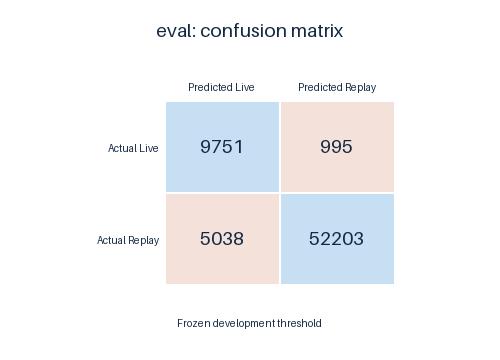

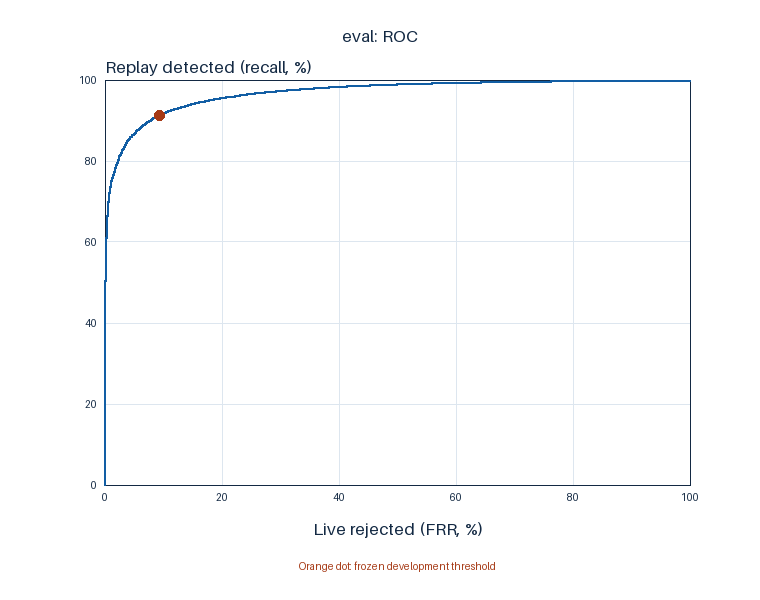

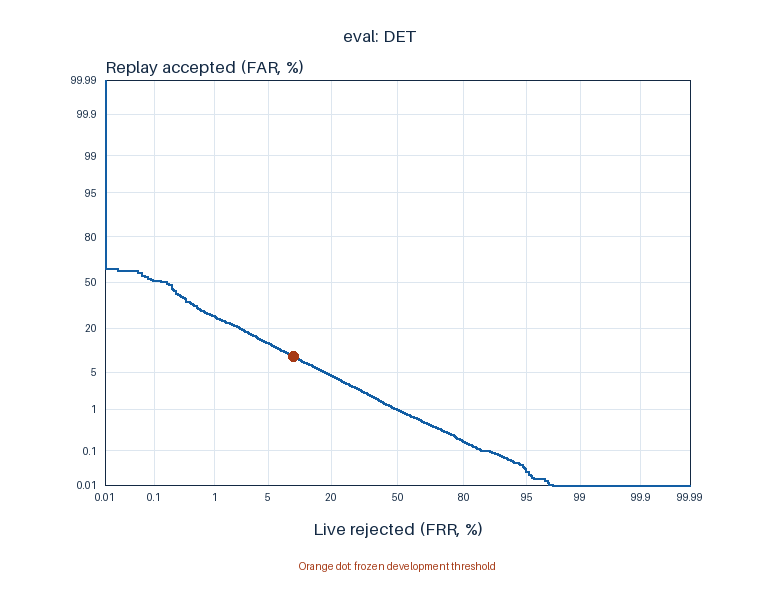

In [100]:
import json
from pathlib import Path
from IPython.display import Image, display

runs = sorted(Path("/content/acoustic-topo-lock-pa/results").glob("full-*"))
print("full runs:", [r.name for r in runs])
run_dir = runs[-1]
report = json.loads((run_dir / "metrics.json").read_text())

print("model:", report["selected_model"], "|", report["model_version"])
print("eval status:", report["eval"]["status"])
for split in ("dev", "eval"):
    print(split, {k: v for k, v in report[split].items() if isinstance(v, (int, float, str))})

split = "eval" if report["eval"]["status"] == "measured" else "dev"
for name in ("confusion", "roc", "det"):
    display(Image(filename=str(run_dir / f"{split}_{name}.png")))

In [102]:
import subprocess, sys
code = f'''
from replay_detection import load_replay_model
d = load_replay_model(r"{run_dir}")
print("Verified", d.model_version)
'''
subprocess.run([sys.executable, "-c", code], cwd=MODULE, check=True)

CompletedProcess(args=['/usr/bin/python3', '-c', '\nfrom replay_detection import load_replay_model\nd = load_replay_model(r"/content/acoustic-topo-lock-pa/results/full-20261119T001653372142Z")\nprint("Verified", d.model_version)\n'], returncode=0)

In [104]:
from google.colab import drive
import shutil
drive.mount("/content/drive")
shutil.copytree("/content/acoustic-topo-lock-pa/results", "/content/drive/MyDrive/acoustic-topo-lock-results", dirs_exist_ok=True)
print("saved")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saved


In [108]:
print("model:", report["selected_model"], "|", report["model_version"])
for split in ("dev", "eval"):
    print("---", split)
    for k, v in report[split].items():
        if isinstance(v, (int, float, str)):
            print(k, round(v, 5) if isinstance(v, float) else v)

model: all_logistic | pa2019-r1-e74877715f5d53d6
--- dev
trials 15434
threshold 0.28392
accuracy 0.92037
precision_replay 0.97774
recall_replay 0.92034
f1_replay 0.94817
roc_auc 0.9743
eer 0.07966
far 0.07966
frr 0.07953
replay_attack_acceptance_rate 0.07966
--- eval
status measured
trials 67987
threshold 0.28392
accuracy 0.91126
precision_replay 0.9813
recall_replay 0.91199
f1_replay 0.94537
roc_auc 0.96936
eer 0.08989
far 0.08801
frr 0.09259
replay_attack_acceptance_rate 0.08801


In [110]:
import json
print(json.dumps(report["split_processing"], indent=2))
print(json.dumps(report["dataset"], indent=2)[:3000])

{
  "train": {
    "requested": 54000,
    "accepted": 27406,
    "quality_counts": {
      "ok": 27402,
      "warning": 4
    },
    "excluded_by_reason": {
      "unreadable_or_unsupported_audio": 26594
    },
    "excluded_by_label": {
      "0": 2252,
      "1": 24342
    },
    "feature_seconds": 635.3558497110007
  },
  "dev": {
    "requested": 29700,
    "accepted": 15434,
    "quality_counts": {
      "ok": 15431,
      "warning": 3
    },
    "excluded_by_reason": {
      "unreadable_or_unsupported_audio": 14266
    },
    "excluded_by_label": {
      "0": 2181,
      "1": 12085
    },
    "feature_seconds": 349.5023540889997
  },
  "eval": {
    "requested": 134730,
    "accepted": 67987,
    "quality_counts": {
      "ok": 67987
    },
    "excluded_by_reason": {
      "unreadable_or_unsupported_audio": 66743
    },
    "excluded_by_label": {
      "0": 7344,
      "1": 59399
    },
    "feature_seconds": 1852.37378154
  }
}
{
  "dataset": "ASVspoof 2019 Physical Access (s